<a href="https://colab.research.google.com/github/ZIZOUTOUMOU/LAB02-AdvDB/blob/main/traffic_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA: Metro Interstate Traffic Volume
Hourly westbound I-94 traffic (Minneapolis–St Paul, 2012–2018) with weather and holiday data.

**Before running:** `pip install pandas numpy matplotlib seaborn scipy plotly ucimlrepo`. If the UCI download fails, put `Metro_Interstate_Traffic_Volume.csv` in the same folder as this notebook.

Each code cell has a short note above it: **What** it does and **Why** we need it.

## 1. Setup and data

**What:** Install the libraries (only needed once; harmless if already installed).  
**Why:** `ucimlrepo` lets us download the dataset directly from UCI. Colab may not have it, and the rest are standard.

In [1]:
%pip install -q ucimlrepo plotly seaborn scipy

**What:** Import the libraries and load the dataset into a DataFrame. It tries UCI first, then a local `Metro_Interstate_Traffic_Volume.csv` or `.csv.gz` in the notebook's folder, and on Colab it opens an upload prompt if none is found.  
**Why:** pandas/NumPy handle the data, matplotlib/seaborn draw charts, SciPy gives skewness and kurtosis. `keep_default_na=False` stops pandas from turning the text `"None"` in `holiday` into a missing value.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

def load_data():
    try:
        from ucimlrepo import fetch_ucirepo          # UCI dataset id 492
        return fetch_ucirepo(id=492).data.original.copy()
    except Exception as e:
        print("UCI download failed, trying local file:", repr(e))
    for name in ["Metro_Interstate_Traffic_Volume.csv", "Metro_Interstate_Traffic_Volume.csv.gz"]:
        if os.path.exists(name):
            # keep_default_na=False: otherwise pandas turns the string "None" into NaN
            return pd.read_csv(name, keep_default_na=False)
    try:  # Google Colab: ask the user to upload the file
        from google.colab import files
        up = files.upload()
        return pd.read_csv(list(up.keys())[0], keep_default_na=False)
    except ImportError:
        raise FileNotFoundError("Put Metro_Interstate_Traffic_Volume.csv (or .csv.gz) in the same folder as this notebook: " + os.getcwd())

df = load_data()

**What:** Convert `date_time` to a real datetime, then run `head()`, `info()` and `describe(include='all')`.  
**Why:** This is the required first inspection. It shows column types, row count (48,204), and a first look at ranges. Datetime conversion lets us extract hour and weekday later.

In [3]:
df["date_time"] = pd.to_datetime(df["date_time"])
print(df.head())
df.info()
print(df.describe(include="all"))

  holiday    temp  rain_1h  snow_1h  clouds_all weather_main  \
0     NaN  288.28      0.0      0.0          40       Clouds   
1     NaN  289.36      0.0      0.0          75       Clouds   
2     NaN  289.58      0.0      0.0          90       Clouds   
3     NaN  290.13      0.0      0.0          90       Clouds   
4     NaN  291.14      0.0      0.0          75       Clouds   

  weather_description           date_time  traffic_volume  
0    scattered clouds 2012-10-02 09:00:00            5545  
1       broken clouds 2012-10-02 10:00:00            4516  
2     overcast clouds 2012-10-02 11:00:00            4767  
3     overcast clouds 2012-10-02 12:00:00            5026  
4       broken clouds 2012-10-02 13:00:00            4918  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-

**What:** Check for impossible values (0 K temperatures), extreme outliers (huge rain), duplicate timestamps, and the holiday labelling; then clean `temp` and `holiday`.  
**Why:** Good EDA checks data quality before trusting statistics. We found the holiday label appears only on the midnight row of each holiday, which would bias a naive holiday comparison.

In [4]:
# Data-quality checks (worth mentioning in your report)
print("\nTemp == 0 K rows:", (df["temp"] == 0).sum())          # impossible values
print("Max rain_1h:", df["rain_1h"].max())                     # extreme outlier
print("Duplicate timestamps:", df["date_time"].duplicated().sum())
df["temp"] = df["temp"].replace(0, np.nan)                     # treat as missing
df["holiday"] = df["holiday"].fillna("None")
# Note: the holiday label appears ONLY on the 00:00 row of each holiday (61 rows),
# so "holiday" rows are all midnight hours -> compare with midnight non-holiday rows too.
midnight = df[df["date_time"].dt.hour == 0]
print(midnight.groupby(midnight["holiday"] == "None")["traffic_volume"].median())


Temp == 0 K rows: 10
Max rain_1h: 9831.3
Duplicate timestamps: 7629
holiday
False    812.0
True     672.5
Name: traffic_volume, dtype: float64


**Your interpretation:** _Note the data issues you found and how you handled them._

## 2.1 Summary statistics (non-graphical EDA)

**What:** Compute mean, median, mode, standard deviation and range of `traffic_volume`.  
**Why:** Mean/median/mode describe the centre; std and range describe the spread. Comparing mean and median gives a first hint about skew.

In [5]:
tv = df["traffic_volume"]
print(tv.describe())
print("Mean:", tv.mean(), "| Median:", tv.median(), "| Mode:", tv.mode().iloc[0])
print("Std:", tv.std(), "| Range:", tv.max() - tv.min())

count    48204.000000
mean      3259.818355
std       1986.860670
min          0.000000
25%       1193.000000
50%       3380.000000
75%       4933.000000
max       7280.000000
Name: traffic_volume, dtype: float64
Mean: 3259.8183553232097 | Median: 3380.0 | Mode: 353
Std: 1986.8606704463552 | Range: 7280


**Your interpretation:** _Compare mean vs median. Do you expect symmetric, right-skewed or left-skewed?_

**What:** Calculate skewness and (excess) kurtosis.  
**Why:** Skewness quantifies asymmetry (about 0 = symmetric). Excess kurtosis compares tail weight to a normal curve (below 0 = light-tailed/platykurtic). These turn the visual idea of shape into numbers.

In [6]:
skew = stats.skew(tv)
kurt = stats.kurtosis(tv)       # excess kurtosis (normal = 0)
print(f"Skewness: {skew:.3f} | Excess kurtosis: {kurt:.3f}")
# Interpretation: |skew| < 0.5 ~ roughly symmetric; kurt < 0 -> platykurtic.

Skewness: -0.089 | Excess kurtosis: -1.309


**Your interpretation:** _Interpret the sign and size of both values. Do they match your Task A expectation?_

**What:** Group by `weather_main` and compute count, mean and std of traffic volume.  
**Why:** This is multivariate analysis: how the target changes across a category. Including `count` warns you about rare categories (e.g. Squall) whose statistics are unreliable.

In [7]:
g = df.groupby("weather_main")["traffic_volume"].agg(["count", "mean", "std"]).sort_values("mean", ascending=False)
print(g)
print("Highest mean:", g["mean"].idxmax(), "| Highest std:", g["std"].idxmax())
# Caution: check 'count' - groups with very few rows give unreliable stats.

              count         mean          std
weather_main                                 
Clouds        15164  3618.449749  1906.202879
Haze           1360  3502.101471  1873.511057
Rain           5672  3317.905501  1982.228705
Drizzle        1821  3290.727073  1997.901830
Smoke            20  3237.650000  1978.015893
Clear         13391  3055.908819  1987.101411
Snow           2876  3016.844228  1900.185883
Thunderstorm   1034  3001.620890  1988.296012
Mist           5950  2932.956639  2073.025670
Fog             912  2703.720395  2125.525863
Squall            4  2061.750000  1950.070490
Highest mean: Clouds | Highest std: Fog


**Your interpretation:** _Which weather has the highest mean? Which has the highest std? Mention small groups._

## 2.2 Graphical EDA

**What:** Histogram of `traffic_volume` with a dashed mean line, an action title and labelled axes.  
**Why:** A histogram shows the full shape of the distribution, which numbers alone can hide. Here it reveals two humps (quiet and busy hours), explaining the negative kurtosis.

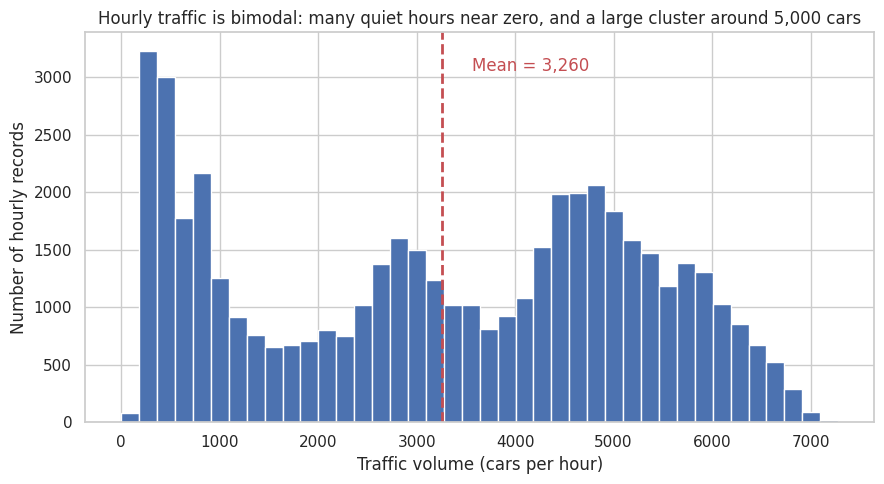

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(tv, bins=40, color="#4C72B0", edgecolor="white")
ax.axvline(tv.mean(), color="#C44E52", linestyle="--", linewidth=2)
ax.annotate(f"Mean = {tv.mean():,.0f}", xy=(tv.mean(), ax.get_ylim()[1] * 0.9),
            xytext=(tv.mean() + 300, ax.get_ylim()[1] * 0.9), color="#C44E52")
ax.set_title("Hourly traffic is bimodal: many quiet hours near zero, and a large cluster around 5,000 cars")
ax.set_xlabel("Traffic volume (cars per hour)")
ax.set_ylabel("Number of hourly records")
plt.tight_layout(); plt.show()

**What:** Compute Q1, median, Q3 and the IQR, then draw a box plot.  
**Why:** The box plot summarises dispersion robustly. IQR = Q3 − Q1 is the spread of the middle 50% of hours and isn't affected by outliers.

Q1=1193, Median=3380, Q3=4933, IQR=3740


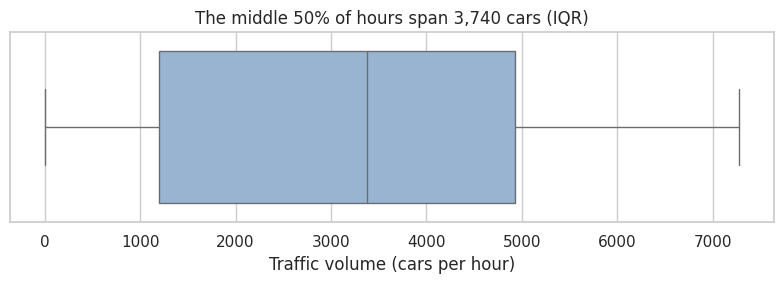

In [9]:
q1, q2, q3 = tv.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
print(f"Q1={q1:.0f}, Median={q2:.0f}, Q3={q3:.0f}, IQR={iqr:.0f}")
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(x=tv, ax=ax, color="#8FB4D9")
ax.set_title(f"The middle 50% of hours span {iqr:,.0f} cars (IQR)")
ax.set_xlabel("Traffic volume (cars per hour)")
plt.tight_layout(); plt.show()

**Your interpretation:** _Report the IQR and relate it to the overall variability._

**What:** Side-by-side box plots of traffic volume for holiday vs non-holiday rows (and per named holiday), using position rather than colour.  
**Why:** Comparing distributions across a category shows whether holidays change traffic level and spread. Using position keeps the chart readable without relying on colour. Remember the holiday rows are all midnight hours, so interpret carefully.

holiday
None                         48143
Labor Day                        7
Christmas Day                    6
Thanksgiving Day                 6
Martin Luther King Jr Day        6
New Years Day                    6
Veterans Day                     5
Columbus Day                     5
Memorial Day                     5
Washingtons Birthday             5
State Fair                       5
Independence Day                 5
Name: count, dtype: int64


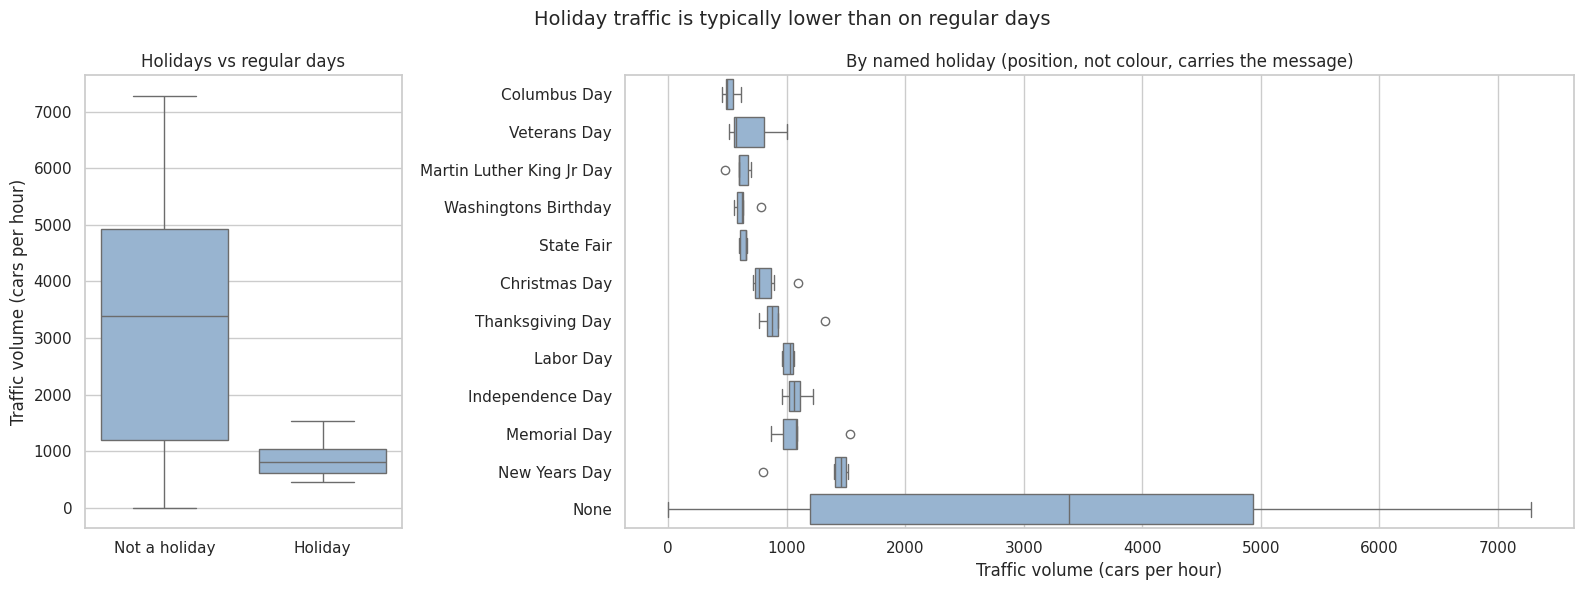

                 count         mean          std    min     25%     50%  \
is_holiday                                                                
Holiday           61.0   865.442623   291.028952  455.0   615.0   812.0   
Not a holiday  48143.0  3262.852170  1986.262390    0.0  1198.0  3385.0   

                  75%     max  
is_holiday                     
Holiday        1041.0  1538.0  
Not a holiday  4934.0  7280.0  


In [10]:
df["is_holiday"] = np.where(df["holiday"].fillna("None") == "None", "Not a holiday", "Holiday")
print(df["holiday"].value_counts())
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 3]})

sns.boxplot(data=df, x="is_holiday", y="traffic_volume", ax=axes[0], color="#8FB4D9")
axes[0].set_title("Holidays vs regular days")
axes[0].set_xlabel(""); axes[0].set_ylabel("Traffic volume (cars per hour)")

order = df.groupby("holiday")["traffic_volume"].median().sort_values().index
sns.boxplot(data=df, y="holiday", x="traffic_volume", order=order, ax=axes[1], color="#8FB4D9")
axes[1].set_title("By named holiday (position, not colour, carries the message)")
axes[1].set_xlabel("Traffic volume (cars per hour)"); axes[1].set_ylabel("")
fig.suptitle("Holiday traffic is typically lower than on regular days", fontsize=14)
plt.tight_layout(); plt.show()

print(df.groupby("is_holiday")["traffic_volume"].describe())

**Your interpretation:** _Does the spread differ between typical and holiday days? Mention the midnight caveat._

## 2.3 Correlation

**What:** Correlation matrix of the numeric columns and a heatmap.  
**Why:** The heatmap shows at a glance which variables move together, so you can pick the strongest relationship with traffic volume.

                traffic_volume   temp  rain_1h  snow_1h  clouds_all
traffic_volume           1.000  0.132    0.005    0.001       0.067
temp                     0.132  1.000    0.009   -0.021      -0.113
rain_1h                  0.005  0.009    1.000   -0.000       0.005
snow_1h                  0.001 -0.021   -0.000    1.000       0.028
clouds_all               0.067 -0.113    0.005    0.028       1.000


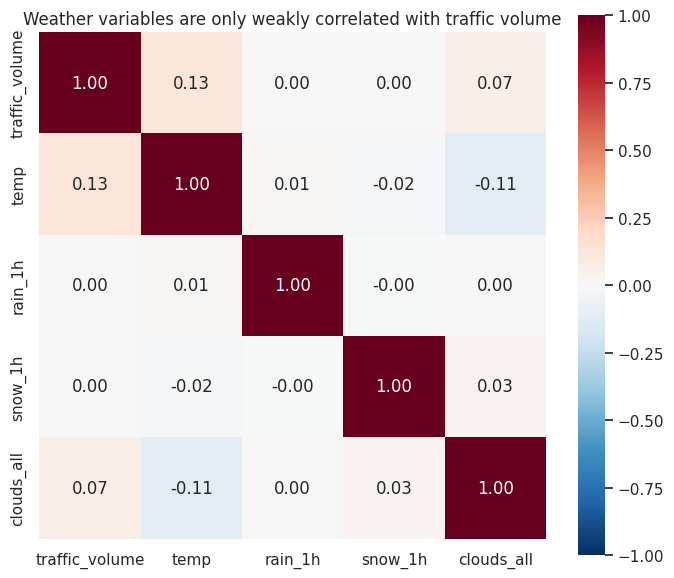

In [11]:
num_cols = ["traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all"]
corr = df[num_cols].corr()
print(corr.round(3))
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Weather variables are only weakly correlated with traffic volume")
plt.tight_layout(); plt.show()

**What:** Find the environmental variable with the strongest absolute correlation, then check average traffic and temperature by hour of day and by weekday vs weekend.  
**Why:** Correlation is not causation. Time of day affects both temperature and traffic (a confounder), and the hourly view shows traffic follows commuting patterns, not weather.

Strongest: temp (r = 0.132)
      traffic_volume   temp
hour                       
0              834.8  279.9
1              516.4  279.5
2              388.4  279.3
3              371.1  279.2
4              702.6  278.8
5             2094.6  278.8
6             4140.5  278.6
7             4740.2  278.6
8             4587.5  278.8
9             4385.3  279.7
10            4184.7  280.6
11            4465.9  281.9
12            4718.3  282.9
13            4714.9  283.4
14            4931.9  284.3
15            5240.5  284.6
16            5663.8  284.5
17            5310.1  284.4
18            4263.7  284.4
19            3276.4  283.4
20            2834.7  282.7
21            2668.9  281.8
22            2199.4  281.0
23            1469.1  280.4


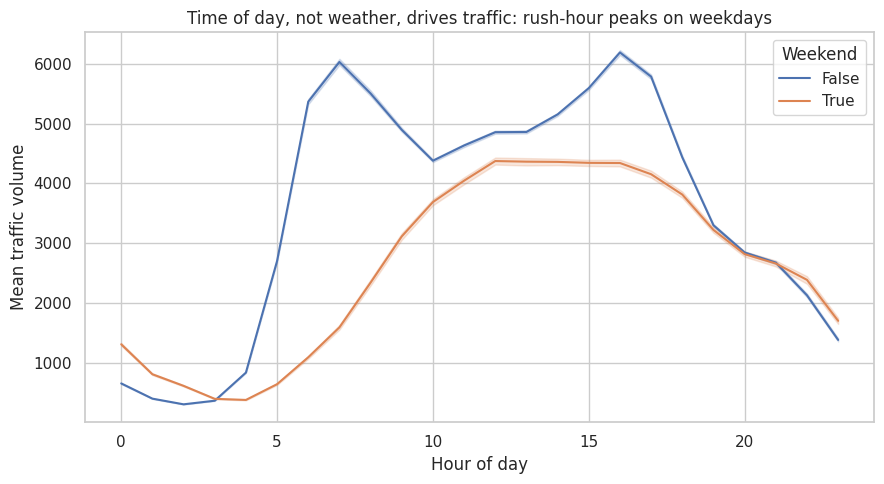

In [12]:
env = corr["traffic_volume"].drop("traffic_volume")
best = env.abs().idxmax()
print(f"Strongest: {best} (r = {env[best]:.3f})")

# Confounder check: time of day drives both temperature and traffic.
df["hour"] = df["date_time"].dt.hour
df["weekday"] = df["date_time"].dt.dayofweek
print(df.groupby("hour")[["traffic_volume", "temp"]].mean().round(1))

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=df, x="hour", y="traffic_volume", hue=df["weekday"] >= 5, ax=ax)
ax.set_title("Time of day, not weather, drives traffic: rush-hour peaks on weekdays")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Mean traffic volume")
ax.legend(title="Weekend")
plt.tight_layout(); plt.show()

**Your interpretation:** _Name the strongest variable and its sign. Explain why it isn't causal and name the confounder._

## 2.4 Interactive chart (bonus)

**What:** Plotly scatter of temperature vs traffic volume with `weather_description` shown on hover (8,000-row sample).  
**Why:** Interactivity lets you inspect individual points. Sampling keeps the chart fast, and the action title states the main finding.

In [13]:
import plotly.express as px
sample = df.dropna(subset=["temp"]).sample(8000, random_state=0)
fig = px.scatter(sample, x="temp", y="traffic_volume", color="is_holiday",
                 hover_data=["weather_description", "date_time"], opacity=0.5,
                 labels={"temp": "Temperature (K)", "traffic_volume": "Traffic volume (cars/hour)"},
                 title="Traffic volume varies widely at every temperature; temperature alone does not predict it")
fig.show()

**Your interpretation:** _What does the plot show about temperature and traffic?_